# AttentionBaseNet vs EEGNet: cross-Subject transfer ablation

## 1. Objective
This notebook evaluates a channel-attention CNN (`AttentionBaseNet` from `braindecode`) against the purely convolutional baseline (`EEGNet`) developed in the previous notebook. 

## 2. Experimental procedure
To ensure a **fair 1:1 comparison**, I maintain the exact same Cross-Subject evaluation protocol established for EEGNet:
*   **Training subjects:** ['A01T', 'A03T', 'A05T', 'A06T', 'A08T']
*   **Validation subjects:** ['A04T', 'A07T']
*   **Test subjects:** ['A02T', 'A09T'] (completely unseen until final inference)

I evaluate the impact of the **Squeeze-and-Excitation (SE)** attention module, both with and without training-only Gaussian noise augmentation ($\sigma = 0.05$).

## Setup, Path check e costants

In [1]:
import os
import time
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

import torch
from torch.utils.data import TensorDataset, DataLoader
import mne
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Braindecode architecture
from braindecode.models import AttentionBaseNet

# 1. Reproducibility
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Create directory to save models
os.makedirs('saved_models', exist_ok=True)

# 2. Data Constants
CLEAN_DATA_DIR = os.path.join('.', 'cleaned_data_1_40')
EVENT_ID = {'left': 1, 'right': 2, 'foot': 3, 'tongue': 4}
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Foot', 'Tongue']
T_MIN, T_MAX = 0.5, 3.5
ALL_SUBJECTS = [f'A{i:02d}T' for i in range(1, 10)]

# Strict Split Definition (Identical to EEGNet experiment)
TRAIN_SUBJECTS = ['A01T', 'A03T', 'A05T', 'A06T', 'A08T']
VAL_SUBJECTS   = ['A04T', 'A07T']
TEST_SUBJECTS  = ['A02T', 'A09T']

Using device: cpu


## Dynamic load and tensor preparation

In [2]:
def load_subject(subject_id):
    """Loads raw .fif, epochs, and applies per-trial Z-score normalisation."""
    file_path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    raw.pick(['eeg'])
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=T_MIN, tmax=T_MAX,
                        baseline=None, preload=True, verbose=False)
    
    X = epochs.get_data(copy=True).astype(np.float32)
    y = epochs.events[:, -1] - 1
    
    # Z-score per trial, per channel
    X = (X - X.mean(axis=-1, keepdims=True)) / (X.std(axis=-1, keepdims=True) + 1e-8)
    return X, y

data = {}
print("Loading all subjects into memory...")
for sub in ALL_SUBJECTS:
    data[sub] = load_subject(sub)

# Dynamically derive input shapes
X_example, _ = data[ALL_SUBJECTS[0]]
N_CHANS = X_example.shape[1]
N_TIMES = X_example.shape[2]
N_CLASSES = len(CLASS_NAMES)
print(f"Derived Input Shape: {N_CHANS} channels x {N_TIMES} samples")

def stack(subjects):
    """Concatenates numpy arrays for a given list of subjects."""
    X_stacked = np.concatenate([data[s][0] for s in subjects], axis=0)
    y_stacked = np.concatenate([data[s][1] for s in subjects], axis=0)
    return X_stacked, y_stacked

def prep_tensors(X, y):
    """Removes trailing dummy dimensions and converts to PyTorch tensors."""
    if len(X.shape) == 4: 
        X = np.squeeze(X, axis=-1)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

def add_gaussian_noise(X_torch, std=0.05):
    noise = torch.randn_like(X_torch) * std
    return X_torch + noise

Loading all subjects into memory...
Derived Input Shape: 22 channels x 751 samples


In [3]:
import copy

def train_model(model, X_tr, y_tr, X_va, y_va, epochs=60, patience=15, lr=1e-3, batch_size=32, augment=False):
    """Trains the model and restores the best validation-loss checkpoint using deepcopy."""
    
    if augment:
        X_tr_noisy = add_gaussian_noise(X_tr, std=0.05)
        X_tr = torch.cat([X_tr, X_tr_noisy], dim=0)
        y_tr = torch.cat([y_tr, y_tr], dim=0)
        
    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=int(batch_size), shuffle=True)
    val_loader = DataLoader(TensorDataset(X_va, y_va), batch_size=int(batch_size), shuffle=False)
    
    model = model.to(device)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float("inf")
    best_model_state = None
    patience_counter = 0
    
    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            
        model.eval()
        total_val_loss = 0.0
        total_val_samples = 0
        
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                logits = model(X_batch)
                batch_loss = criterion(logits, y_batch)
                total_val_loss += batch_loss.item() * len(y_batch)
                total_val_samples += len(y_batch)
                
        val_loss = total_val_loss / total_val_samples
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
                
    model.load_state_dict(best_model_state)
    return model, best_val_loss, epoch + 1

## Grid search

In [4]:
PARAM_GRID_ATTN = {
    'learning_rate': [0.001, 0.0005, 0.0001],
    'dropout_rate': [0.4, 0.5, 0.6],
    'batch_size': [16, 32]
}

keys, values = zip(*PARAM_GRID_ATTN.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
attn_search_results = []

# Prepare tensors for Train and Validation subjects only
X_tr_t, y_tr_t = prep_tensors(*stack(TRAIN_SUBJECTS))
X_va_t, y_va_t = prep_tensors(*stack(VAL_SUBJECTS))

print(f"Starting AttentionBaseNet Grid Search: testing {len(combinations)} combinations on validation subjects {VAL_SUBJECTS}...")

for i, params in enumerate(combinations, 1):
    set_seed()
    model = AttentionBaseNet(
        n_chans=N_CHANS,
        n_outputs=N_CLASSES,
        n_times=N_TIMES,
        attention_mode="se",
        drop_prob_inp=params['dropout_rate'],
        drop_prob_attn=params['dropout_rate']
    )
    
    best_model, best_val_loss, _ = train_model(
        model, X_tr_t, y_tr_t, X_va_t, y_va_t,
        epochs=30, patience=10, lr=params['learning_rate'], 
        batch_size=params['batch_size'], augment=False
    )
    
    best_model.eval()
    val_loader = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=int(params['batch_size']), shuffle=False)
    correct, total = 0, 0
    with torch.no_grad():
        for X_b, y_b in val_loader:
            X_b = X_b.to(device)
            outputs = best_model(X_b)
            _, preds = torch.max(outputs, 1)
            total += y_b.size(0)
            correct += (preds.cpu() == y_b).sum().item()
            
    val_acc = correct / total
    attn_search_results.append({**params, 'val_accuracy': val_acc})
    print(f"[{i}/{len(combinations)}] Params: {params} -> Val Accuracy: {val_acc:.3f}")

# Rank the configurations
attn_results_df = pd.DataFrame(attn_search_results).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
print("\n--- AttentionBaseNet Grid Search Rankings ---")
display(attn_results_df)

# Select best parameters
best_attn_params = attn_results_df.iloc[0].to_dict()
print(f"\nBest AttentionBaseNet Config: LR={best_attn_params['learning_rate']}, "
      f"Dropout={best_attn_params['dropout_rate']}, Batch Size={int(best_attn_params['batch_size'])}")

Starting AttentionBaseNet Grid Search: testing 18 combinations on validation subjects ['A04T', 'A07T']...
[1/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 16} -> Val Accuracy: 0.490
[2/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.4, 'batch_size': 32} -> Val Accuracy: 0.488
[3/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.5, 'batch_size': 16} -> Val Accuracy: 0.491
[4/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.5, 'batch_size': 32} -> Val Accuracy: 0.509
[5/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.6, 'batch_size': 16} -> Val Accuracy: 0.488
[6/18] Params: {'learning_rate': 0.001, 'dropout_rate': 0.6, 'batch_size': 32} -> Val Accuracy: 0.493
[7/18] Params: {'learning_rate': 0.0005, 'dropout_rate': 0.4, 'batch_size': 16} -> Val Accuracy: 0.462
[8/18] Params: {'learning_rate': 0.0005, 'dropout_rate': 0.4, 'batch_size': 32} -> Val Accuracy: 0.498
[9/18] Params: {'learning_rate': 0.0005, 'dropout_rate': 0.5, 'batch_size': 

,learning_rate,dropout_rate,batch_size,val_accuracy
0,0.0010,0.5,32,0.508681
1,0.0005,0.4,32,0.498264
2,0.0010,0.6,32,0.493056
3,0.0010,0.5,16,0.491319
4,0.0005,0.5,32,0.491319
5,0.0010,0.4,16,0.489583
6,0.0010,0.4,32,0.487847
7,0.0010,0.6,16,0.487847
8,0.0005,0.5,16,0.480903
9,0.0005,0.6,16,0.470486



Best AttentionBaseNet Config: LR=0.001, Dropout=0.5, Batch Size=32


## Evaluation and ablation


Training AttentionBaseNet (Baseline)
Training finished in 257.6s | Best Val Loss: 1.1449 (Epoch 57)

Detailed Classification Report (Baseline):
              precision    recall  f1-score   support

   Left Hand       0.57      0.27      0.37       144
  Right Hand       0.48      0.52      0.50       144
        Foot       0.39      0.53      0.45       144
      Tongue       0.61      0.65      0.63       144

    accuracy                           0.49       576
   macro avg       0.51      0.49      0.48       576
weighted avg       0.51      0.49      0.48       576


Training AttentionBaseNet (Augmented)
Training finished in 263.4s | Best Val Loss: 1.1727 (Epoch 31)

Detailed Classification Report (Augmented):
              precision    recall  f1-score   support

   Left Hand       0.62      0.33      0.43       144
  Right Hand       0.50      0.47      0.49       144
        Foot       0.33      0.59      0.42       144
      Tongue       0.64      0.47      0.54       144

 

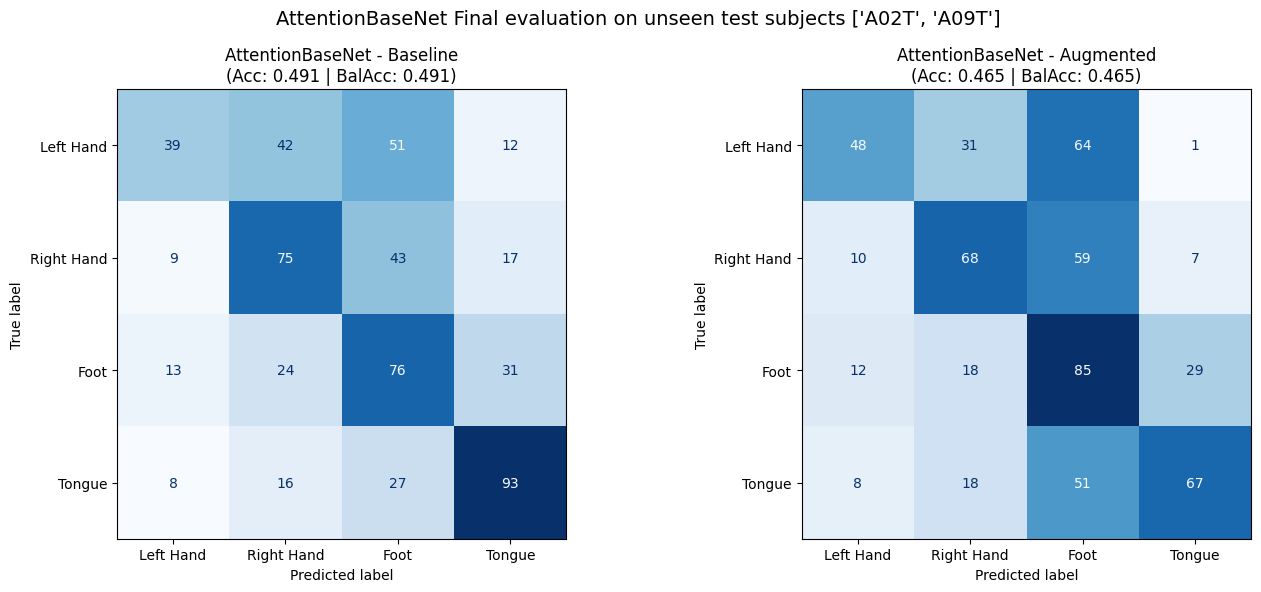


=== Final Summary Table: AttentionBaseNet vs Baseline Splits ===


,Model,Condition,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,AttentionBaseNet,Baseline,0.491319,0.491319,0.509139,0.491319,0.484137,0.484137
1,AttentionBaseNet,Augmented,0.465278,0.465278,0.522876,0.465278,0.470512,0.470512


In [5]:
# Aggiunta degli import necessari per risolvere il NameError
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

X_te_t, y_te_t = prep_tensors(*stack(TEST_SUBJECTS))
te_loader = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=int(best_attn_params['batch_size']), shuffle=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'AttentionBaseNet Final evaluation on unseen test subjects {TEST_SUBJECTS}', fontsize=14)

final_evaluation_results = []

for j, use_aug in enumerate([False, True]):
    cond_name = "Augmented" if use_aug else "Baseline"
    print(f"\n{'='*40}\nTraining AttentionBaseNet ({cond_name})\n{'='*40}")
    
    set_seed()
    model = AttentionBaseNet(
        n_chans=N_CHANS,
        n_outputs=N_CLASSES,
        n_times=N_TIMES,
        attention_mode="se",
        drop_prob_inp=best_attn_params['dropout_rate'],
        drop_prob_attn=best_attn_params['dropout_rate']
    )
    
    start_time = time.time()
    best_model, best_val_loss, epochs_trained = train_model(
        model, X_tr_t, y_tr_t, X_va_t, y_va_t,
        epochs=100, patience=20, lr=best_attn_params['learning_rate'], augment=use_aug
    )
    train_time = time.time() - start_time
    print(f"Training finished in {train_time:.1f}s | Best Val Loss: {best_val_loss:.4f} (Epoch {epochs_trained})")
    
    # Save model checkpoint with complete metadata
    checkpoint = {
        "model_name": "AttentionBaseNet",
        "attention_mode": "se",
        "condition": cond_name,
        "best_params": best_attn_params,
        "test_subjects": TEST_SUBJECTS,
        "model_state_dict": best_model.state_dict()
    }
    torch.save(checkpoint, f"saved_models/AttentionBaseNet_Best_{cond_name}.pth")
    
    # Inference on Test Subjects
    best_model.eval()
    test_preds, test_targets = [], []
    with torch.no_grad():
        for X_b, y_b in te_loader:
            X_b = X_b.to(device)
            outputs = best_model(X_b)
            _, predicted = torch.max(outputs, 1)
            test_preds.extend(predicted.cpu().numpy())
            test_targets.extend(y_b.numpy())
            
    # Detailed Metrics computation
    report_dict = classification_report(test_targets, test_preds, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    
    acc = accuracy_score(test_targets, test_preds)
    balanced_acc = balanced_accuracy_score(test_targets, test_preds)
    macro_f1 = f1_score(test_targets, test_preds, average="macro", zero_division=0)
    
    print(f"\nDetailed Classification Report ({cond_name}):")
    print(classification_report(test_targets, test_preds, target_names=CLASS_NAMES, zero_division=0))
    
    final_evaluation_results.append({
        "Model": "AttentionBaseNet",
        "Condition": cond_name,
        "Accuracy": acc,
        "Balanced Accuracy": balanced_acc,
        "Macro Precision": report_dict['macro avg']['precision'],
        "Macro Recall": report_dict['macro avg']['recall'],
        "Macro F1": macro_f1,
        "Weighted F1": report_dict['weighted avg']['f1-score']
    })
    
    # Plot Confusion Matrix
    cm = confusion_matrix(test_targets, test_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[j], cmap='Blues', colorbar=False, values_format='d')
    axes[j].set_title(f'AttentionBaseNet - {cond_name}\n(Acc: {acc:.3f} | BalAcc: {balanced_acc:.3f})')

plt.tight_layout()
plt.savefig("saved_plots/AttentionBaseNet_Final_CM.png", dpi=200)
plt.show()

# Summary Comparison Table
final_eval_df = pd.DataFrame(final_evaluation_results)
print("\n=== Final Summary Table: AttentionBaseNet vs Baseline Splits ===")
try:
    display(final_eval_df)
except NameError:
    print(final_eval_df)

## Ablation study

In [ ]:
from sklearn.metrics import balanced_accuracy_score, f1_score

ABLATION_SEEDS = [0, 1, 2]
attention_ablation_rows = []

print("Running AttentionBaseNet Ablation Study across multiple seeds...")

def evaluate_attention_condition(condition_name, use_aug):
    seed_balanced_accs = []
    seed_macro_f1s = []
    
    for seed in ABLATION_SEEDS:
        # Reset seed for weights initialization and noise generation
        set_seed(seed)
        
        model = AttentionBaseNet(
            n_chans=N_CHANS,
            n_outputs=N_CLASSES,
            n_times=N_TIMES,
            attention_mode="se",
            drop_prob_inp=best_attn_params['dropout_rate'],
            drop_prob_attn=best_attn_params['dropout_rate']
        )
        
        # Train using the best hyperparameters found via Grid Search
        best_model, _, _ = train_model(
            model, X_tr_t, y_tr_t, X_va_t, y_va_t,
            epochs=60, patience=15, lr=best_attn_params['learning_rate'], augment=use_aug
        )
        
        # Evaluate performance on validation subjects
        best_model.eval()
        val_loader = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=int(best_attn_params['batch_size']), shuffle=False)
        all_preds, all_targets = [], []
        
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b = X_b.to(device)
                outputs = best_model(X_b)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(y_b.numpy())
                
        # Compute robust metrics
        bal_acc = balanced_accuracy_score(all_targets, all_preds)
        macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
        
        seed_balanced_accs.append(bal_acc)
        seed_macro_f1s.append(macro_f1)
        print(f"  Condition: {condition_name} | Seed {seed} -> Bal Acc: {bal_acc:.3f} | Macro F1: {macro_f1:.3f}")
        
    return {
        "Condition": condition_name,
        "Bal Acc (Mean)": np.mean(seed_balanced_accs),
        "Bal Acc (Std)": np.std(seed_balanced_accs),
        "Macro F1 (Mean)": np.mean(seed_macro_f1s),
        "Macro F1 (Std)": np.std(seed_macro_f1s),
        "Seeds": len(ABLATION_SEEDS)
    }

# Execute ablation conditions
attention_ablation_rows.append(evaluate_attention_condition("AttentionBaseNet (NoAug)", use_aug=False))
attention_ablation_rows.append(evaluate_attention_condition("AttentionBaseNet (Augmented)", use_aug=True))

# Display summary dataframe
attn_ablation_df = pd.DataFrame(attention_ablation_rows)
print("\n=== AttentionBaseNet Ablation Summary (Mean +/- Std) ===")
try:
    display(attn_ablation_df.round(3))
except NameError:
    print(attn_ablation_df.round(3))

Running AttentionBaseNet Ablation Study across multiple seeds...
  Condition: AttentionBaseNet (NoAug) | Seed 0 -> Bal Acc: 0.457 | Macro F1: 0.458
  Condition: AttentionBaseNet (NoAug) | Seed 1 -> Bal Acc: 0.493 | Macro F1: 0.495
  Condition: AttentionBaseNet (NoAug) | Seed 2 -> Bal Acc: 0.498 | Macro F1: 0.499
  Condition: AttentionBaseNet (Augmented) | Seed 0 -> Bal Acc: 0.486 | Macro F1: 0.490
  Condition: AttentionBaseNet (Augmented) | Seed 1 -> Bal Acc: 0.510 | Macro F1: 0.515
  Condition: AttentionBaseNet (Augmented) | Seed 2 -> Bal Acc: 0.502 | Macro F1: 0.501

=== AttentionBaseNet Ablation Summary (Mean +/- Std) ===


,Condition,Bal Acc (Mean),Bal Acc (Std),Macro F1 (Mean),Macro F1 (Std),Seeds
0,AttentionBaseNet (NoAug),0.483,0.019,0.484,0.018,3
1,AttentionBaseNet (Augmented),0.499,0.010,0.502,0.010,3


<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
C:\Users\ACER\AppData\Local\Temp\ipykernel_17256\4248972152.py:31: SyntaxWarning: invalid escape sequence '\s'
  ax.set_title('AttentionBaseNet Ablation Study: NoAug vs. Gaussian Augmentation ($\sigma=0.05$)', fontsize=12, fontweight='bold')


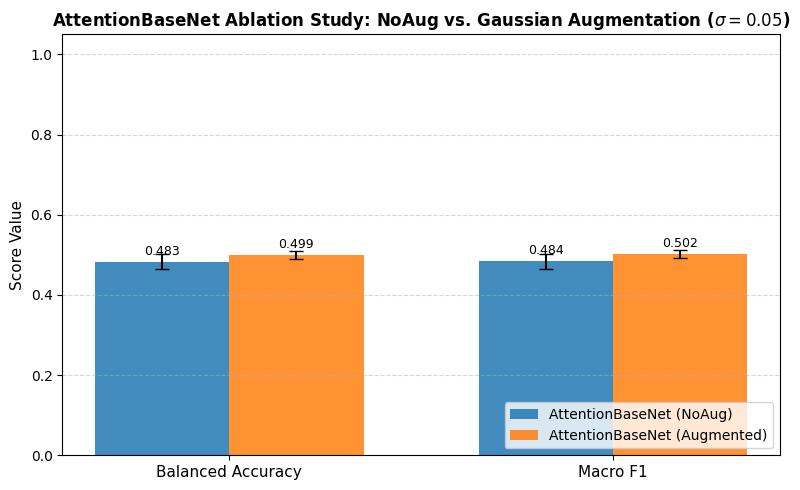

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Extract metrics from the ablation dataframe
metrics = ['Balanced Accuracy', 'Macro F1']
conditions = attn_ablation_df['Condition'].tolist()

# Organize means and standard deviations for plotting
means = [
    [attn_ablation_df.loc[0, 'Bal Acc (Mean)'], attn_ablation_df.loc[0, 'Macro F1 (Mean)']],
    [attn_ablation_df.loc[1, 'Bal Acc (Mean)'], attn_ablation_df.loc[1, 'Macro F1 (Mean)']]
]

stds = [
    [attn_ablation_df.loc[0, 'Bal Acc (Std)'], attn_ablation_df.loc[0, 'Macro F1 (Std)']],
    [attn_ablation_df.loc[1, 'Bal Acc (Std)'], attn_ablation_df.loc[1, 'Macro F1 (Std)']]
]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Plot grouped bars with error bars (standard deviation across seeds)
rects1 = ax.bar(x - width/2, means[0], width, yerr=stds[0], capsize=5, label=conditions[0], color='#1f77b4', alpha=0.85)
rects2 = ax.bar(x + width/2, means[1], width, yerr=stds[1], capsize=5, label=conditions[1], color='#ff7f0e', alpha=0.85)

# Styling the plot
ax.set_ylabel('Score Value', fontsize=11)
ax.set_title('AttentionBaseNet Ablation Study: NoAug vs. Gaussian Augmentation ($\sigma=0.05$)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.05) # Aumentato leggermente
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Function to attach value labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
os.makedirs('saved_plots', exist_ok=True)
plt.savefig('saved_plots/AttentionBaseNet_Ablation_Comparison.png', dpi=200)
plt.show()

## **Conclusion**

The ablation study shows that applying training-only Gaussian noise ($\sigma = 0.05$) to AttentionBaseNet resulted in a mean validation accuracy of $0.49 \pm 0.01$, compared to $0.48 \pm 0.02$ for the unaugmented baseline, due to the overlapping standard deviations, this variation is likely driven by seed-to-seed fluctuations rather than a genuine stabilization of cross-subject transfer.

### **Next step: Leave-One-Subject-Out (LOSO) validation**
To evaluate whether this augmentation holds any generalization power under real-world domain shifts, **next step implements a Leave-One-Subject-Out (LOSO) cross-validation scheme**. 

This protocol will force the network to adapt to completely unseen individuals, allowing to isolate the biological inter-subject variability from seed-to-seed training randomness.